# **Primeiros passos em análises de dados e visualizações gráficas com Python**

# **Dia 3 - Estatística Descritiva e Visualizações Gráficas**

### **Preparando o ambiente**

In [ ]:
# importamos módulo que faz a conexão entre Google Colab e Drive
from google.colab import drive

# solicitar autorização para acessar a sua conta do Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# importando biblioteca pandas
import pandas as pd
import numpy as np

In [ ]:
# lendo uma planilha em csv - preencha nas aspas a planilha original
df = pd.read_csv("", index_col = 0)

In [ ]:
# colunas no dataframe original
df.columns

Index(['Nome_comum', 'Especie', 'Ilha', 'Estagio_Reprodutivo', 'Data_ovo',
       'Comprimento_bico', 'Profundidade_bico', 'Comprimento_asa',
       'Massa_corporal', 'Sexo'],
      dtype='object')

In [ ]:
# lendo uma planilha em csv - preencha nas aspas a planilha "limpa"
df_limpo = pd.read_csv("", index_col = 0)

In [ ]:
# colunas no dataframe limpo
df_limpo.columns

# **Ajustes do dia anterior**

In [ ]:
# cria e seleciona a coluna Ano do dataframe original, como fizemos no dia 2
# separar de mês/dia/ano
split_data = df["Data_ovo"].str.split("/", n = 2, expand = True)
# criando nova coluna com ano
df["Ano"] = split_data[2]
df.head()

,Nome_comum,Especie,Ilha,Estagio_Reprodutivo,Data_ovo,Comprimento_bico,Profundidade_bico,Comprimento_asa,Massa_corporal,Sexo,Ano
ID,,,,,,,,,,,
P1,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/11/2007,39.1,18.7,181.0,3750.0,Macho,2007
P2,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/11/2007,39.5,17.4,186.0,3800.0,Fêmea,2007
P3,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,40.3,18.0,195.0,3250.0,Fêmea,2007
P4,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,NaN,NaN,NaN,NaN,NaN,2007
P5,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,36.7,19.3,193.0,3450.0,Fêmea,2007


In [ ]:
# vamos adicionar essa coluna ano ao dataframe limpo usando .join()
df_final = df_limpo.join(df["Ano"])
df_final.head()

,Nome_comum,Especie,Ilha,Estagio_Reprodutivo,Data_ovo,Comprimento_bico,Profundidade_bico,Comprimento_asa,Massa_corporal,Sexo,Ano
ID,,,,,,,,,,,
P1,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/11/2007,39.1,18.7,181.0,3750.0,Macho,2007
P2,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/11/2007,39.5,17.4,186.0,3800.0,Fêmea,2007
P3,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,40.3,18.0,195.0,3250.0,Fêmea,2007
P4,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,NaN,NaN,NaN,NaN,NaN,2007
P5,Pinguim-de-adélia,Pygoscelis adeliae,Torgersen,"Adulto, Estágio de Ovo 1",11/16/2007,36.7,19.3,193.0,3450.0,Fêmea,2007


In [ ]:
# qual o tamanho de df_final ?
df_final.shape

(344, 11)

In [ ]:
# vamos converter a coluna Ano para inteiro no dataframe final
df_final["Ano"] = df_final["Ano"].astype(int)
df_final.dtypes["Ano"]

dtype('int64')

In [ ]:
# filtramos os animais que não foram coletados no ano de 2007
filtro_ano = df_final["Ano"] != 2007
df_final = df_final[filtro_ano]
df_final.shape

(234, 11)

In [ ]:
# como filtramos mais de uma condição ao mesmo tempo e corrigimos os dados
# exemplo fêmeas
df_final["Sexo"].unique()

array(['Fêmea', 'Macho', 'FEMEA', nan, 'Femea', 'MACHO'], dtype=object)

In [ ]:
# como filtramos mais de uma condição ao mesmo tempo e corrigimos os dados
# exemplo fêmeas
df_final["Sexo"] = df_final["Sexo"].replace(["FEMEA", "Femea"], "Fêmea")
df_final["Sexo"].unique()

array(['Fêmea', 'Macho', nan, 'MACHO'], dtype=object)

In [ ]:
# como adicionamos uma linha para outro dataframe ? - exemplo com o pinguim P1
# selecionamos a primeira linha e todas as colunas
linha = df.iloc[[0]]
print(linha)

           Nome_comum             Especie       Ilha  \
ID                                                     
P1  Pinguim-de-adélia  Pygoscelis adeliae  Torgersen   

          Estagio_Reprodutivo    Data_ovo  Comprimento_bico  \
ID                                                            
P1  Adulto,  Estágio de Ovo 1  11/11/2007              39.1   

    Profundidade_bico  Comprimento_asa  Massa_corporal   Sexo   Ano  
ID                                                                   
P1               18.7            181.0          3750.0  Macho  2007  


In [ ]:
# como adicionamos uma linha para outro dataframe ? - exemplo com o pinguim P1
# selecionamos a primeira linha e todas as colunas
df_analise = pd.concat([df_final, linha], ignore_index=False)

In [ ]:
# como ficamos no final
df_analise

,Nome_comum,Especie,Ilha,Estagio_Reprodutivo,Data_ovo,Comprimento_bico,Profundidade_bico,Comprimento_asa,Massa_corporal,Sexo,Ano
ID,,,,,,,,,,,
P51,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/6/2008,39.6,17.7,186.0,3500.0,Fêmea,2008
P52,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/6/2008,40.1,18.9,188.0,4300.0,Macho,2008
P53,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/9/2008,35.0,17.9,190.0,3450.0,Fêmea,2008
P54,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/9/2008,42.0,19.5,200.0,4050.0,Macho,2008
P55,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/9/2008,34.5,18.1,187.0,2900.0,Fêmea,2008
...,...,...,...,...,...,...,...,...,...,...,...
P341,Pinguim-de-barbicha,Pygoscelis antarctica,Dream,"Adulto, Estágio de Ovo 1",11/21/2009,43.5,18.1,202.0,3400.0,Fêmea,2009
P342,Pinguim-de-barbicha,Pygoscelis antarctica,Dream,"Adulto, Estágio de Ovo 1",11/21/2009,49.6,18.2,193.0,3775.0,Macho,2009
P343,Pinguim-de-barbicha,Pygoscelis antarctica,Dream,"Adulto, Estágio de Ovo 1",11/21/2009,50.8,NaN,210.0,4100.0,MACHO,2009


# **Estatística Descritiva**

É possível realizar análises estatísticas descrita agrupando dados do dataframe.

## **Média**

É possível verificar a média de uma coluna com dados numéricos com a função `mean()`.



```
<nome dataframe>[<nome coluna>].mean()
```



In [ ]:
# checar dados com .info()
df_analise.info()

<class 'pandas.core.frame.DataFrame'>
Index: 235 entries, P51 to P1
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Nome_comum           235 non-null    object 
 1   Especie              235 non-null    object 
 2   Ilha                 235 non-null    object 
 3   Estagio_Reprodutivo  235 non-null    object 
 4   Data_ovo             235 non-null    object 
 5   Comprimento_bico     232 non-null    float64
 6   Profundidade_bico    232 non-null    float64
 7   Comprimento_asa      234 non-null    float64
 8   Massa_corporal       231 non-null    float64
 9   Sexo                 231 non-null    object 
 10  Ano                  235 non-null    object 
dtypes: float64(4), object(7)
memory usage: 22.0+ KB


In [ ]:
# média da coluna de comprimento do bico
df_analise["Comprimento_bico"].mean()

np.float64(43.994396551724144)

In [ ]:
# média de todos os valores numéricos
df_analise.mean(numeric_only=True)

,0
Comprimento_bico,43.994397
Profundidade_bico,17.019397
Comprimento_asa,202.709402
Massa_corporal,4233.658009


## **Mediana**

É possível verificar a mediana de uma coluna com dados numéricos com a função `median()`.



```
<nome dataframe>[<nome coluna>].median()
```


In [ ]:
# medianas das colunas numéricas
df_analise.median(numeric_only=True)

,0
Comprimento_bico,44.45
Profundidade_bico,17.10
Comprimento_asa,199.00
Massa_corporal,4100.00


## **Moda**

O valor mais frequente, ou seja, moda, pode ser obtido utilizando a função mode()

```
<nome dataframe>[<nome coluna>].mode()
```

In [ ]:
# qual a espécie mais frequente de pinguim?
df_analise["Especie"].mode()

,Especie
0,Pygoscelis adeliae


In [ ]:
# quantas vezes a espécie mais frequente aparece?
(df_analise["Especie"] == "Pygoscelis adeliae").sum()

np.int64(103)

In [ ]:
# quantas vezes a espécie mais frequente aparece?
int((df_analise["Especie"] == "Pygoscelis adeliae").sum())

103

In [ ]:
# é possível ver a moda para todas as colunas ao mesmo tempo?
df_analise.mode()

,Nome_comum,Especie,Ilha,Estagio_Reprodutivo,Data_ovo,Comprimento_bico,Profundidade_bico,Comprimento_asa,Massa_corporal,Sexo,Ano
0,Pinguim-de-adélia,Pygoscelis adeliae,Biscoe,"Adulto, Estágio de Ovo 1",11/9/2008,41.1,17.0,190.0,4300.0,Macho,2009
1,NaN,NaN,NaN,NaN,NaN,45.2,NaN,NaN,NaN,NaN,NaN


## **Quartis**

Para recuperar os quartis em um conjunto de dados, utilizamos `.quantile()`

```
<nome dataframe>[<nome coluna>].quantile()
```

In [ ]:
# recuperar os quartis das colunas numéricas
df_analise.quantile(numeric_only = True)

,0.5
Comprimento_bico,44.45
Profundidade_bico,17.10
Comprimento_asa,199.00
Massa_corporal,4100.00


In [ ]:
# recuperar os quartis de 25% das colunas numéricas
df_analise.quantile(.25, numeric_only = True)

,0.25
Comprimento_bico,39.6
Profundidade_bico,15.6
Comprimento_asa,191.0
Massa_corporal,3550.0


## **Desvio padrão e variância**

Para recuperar o desvio padrão e variância em um conjunto de dados, utilizamos `.std()` e `var`

```
<nome dataframe>[<nome coluna>].std()
<nome dataframe>[<nome coluna>].var()

In [ ]:
# obtendo o desvio padrão
df_analise.std(numeric_only=True)

,0
Comprimento_bico,5.486198
Profundidade_bico,1.883447
Comprimento_asa,13.800578
Massa_corporal,806.927032


In [ ]:
# obtendo a variância
df_analise.var(numeric_only=True)

,0
Comprimento_bico,30.098367
Profundidade_bico,3.547371
Comprimento_asa,190.455963
Massa_corporal,651131.234707


# **Tabela dinâmica**

O Pandas possui a função groupby() que nos permite agrupar dados.

Por exemplo, ele nos permite visualizar rapidamente uma tabela de frequência.

```
<nome dataframe>.groupby(<"nome coluna">).método()

In [ ]:
# vamos ver um exemplo usando a coluna Especie
# qual a frequência de dados de coluna para cada espécie?
df_analise.groupby("Especie").count()

,Nome_comum,Ilha,Estagio_Reprodutivo,Data_ovo,Comprimento_bico,Profundidade_bico,Comprimento_asa,Massa_corporal,Sexo,Ano
Especie,,,,,,,,,,
Pygoscelis adeliae,103,103,103,103,102,103,103,101,103,103
Pygoscelis antarctica,42,42,42,42,42,41,42,42,42,42
Pygoscelis papua,90,90,90,90,88,88,89,88,86,90


Podemos contar os valores agrupando colunas.

In [ ]:
# podemos agrupar usando duas colunas
df_analise.groupby("Especie")["Sexo"].value_counts()

Especie                Sexo 
Pygoscelis adeliae     Macho    52
                       Fêmea    51
Pygoscelis antarctica  Fêmea    21
                       Macho    20
                       MACHO     1
Pygoscelis papua       Macho    44
                       Fêmea    42
Name: count, dtype: int64

In [ ]:
# podemos agrupar usando duas colunas
df_analise.groupby(["Especie","Sexo"]).size()

Especie                Sexo 
Pygoscelis adeliae     Fêmea    51
                       Macho    52
Pygoscelis antarctica  Fêmea    21
                       MACHO     1
                       Macho    20
Pygoscelis papua       Fêmea    42
                       Macho    44
dtype: int64

E podemos usar as funções de estatística descritiva também com groupby()

In [ ]:
# agrupar e fazendo a media da asa para cada espécie
df_analise.groupby("Especie")["Comprimento_asa"].mean()

,Comprimento_asa
Especie,
Pygoscelis adeliae,191.466019
Pygoscelis antarctica,197.928571
Pygoscelis papua,217.977528


## **Tabela de frequência com múltiplas medidas**

Podemos fazer cálculo de medidas como média e mediana em uma tabela dinâmica utilizando `agg()`, `groupby()` e as função `mean()`, `median()` ou `mode()`

```
<nome dataframe>.groupby("<nome coluna>")["<nome coluna>"].agg([<método, método>]
```



In [ ]:
# obtendo média e mediana da asa de cada espécie
df_analise.groupby("Especie")["Comprimento_asa"].agg(["mean", "median"])

,mean,median
Especie,,
Pygoscelis adeliae,191.466019,191.0
Pygoscelis antarctica,197.928571,198.0
Pygoscelis papua,217.977528,217.0


In [ ]:
# criano boxplot de sexo, profundidade de bico por espécie com seaborn
media_mediana = df_analise.groupby("Especie")["Comprimento_asa"].agg(["mean", "median"])

# **Resumo de estatísticas dos dados**

Use a função .describe() e veja a mágica acontecer!

`<nome dataframe>.describe()`

In [ ]:
# utilize a função .describe() no dataframe penguim


# **Pacotes gráficos**

Python possui pacotes dedicados para visualizações gráficas.

**Algumas bibliotecas disponíveis** <br>
Fonte: https://www.index.dev/blog/python-data-visualization-library <br><br>

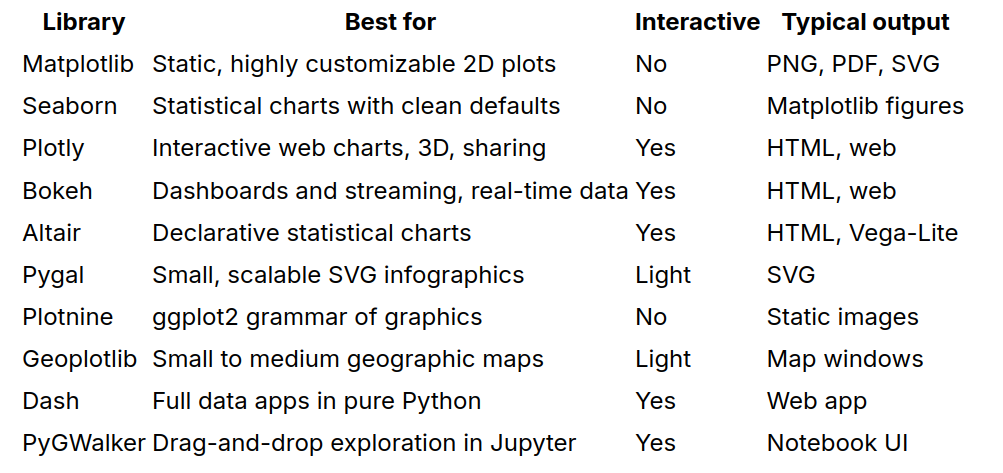

In [ ]:
# importando a biblioteca matplotlib
import matplotlib.pyplot as plt

(array([103.,   0.,   0.,   0.,   0.,  90.,   0.,   0.,   0.,  42.]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

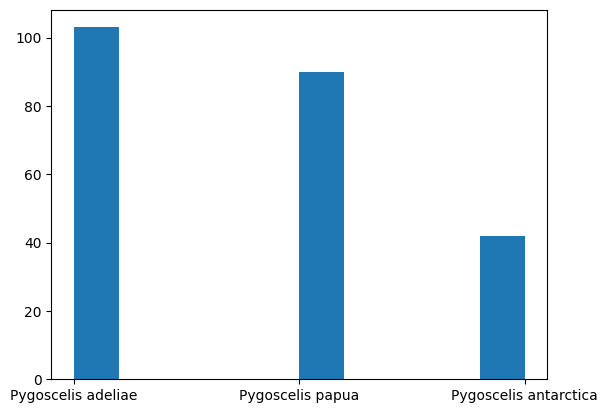

In [ ]:
# frequência de cada espécie
plt.hist(df_analise["Especie"])

In [ ]:
# importando seaborn
import seaborn as sns

<Axes: ylabel='Comprimento_asa'>

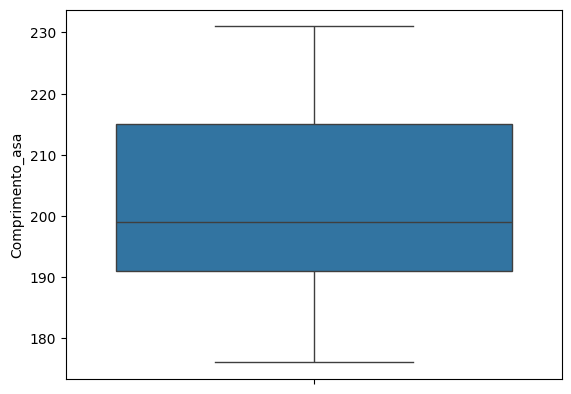

In [ ]:
# boxplot com média, quartil 25% e 75% de comprimento de asa
sns.boxplot(df_analise["Comprimento_asa"])

In [ ]:
 # index P1 repetido
 df_analise["Sexo"]

,Sexo
ID,
P51,Fêmea
P52,Macho
P53,Fêmea
P54,Macho
P55,Fêmea
...,...
P341,Fêmea
P342,Macho
P343,MACHO


In [ ]:
# reindexando os índices de linhas do dataframe
df_analise.reset_index(inplace = True, drop = True)

Text(0.5, 1.0, 'Pinguins de Palmer')

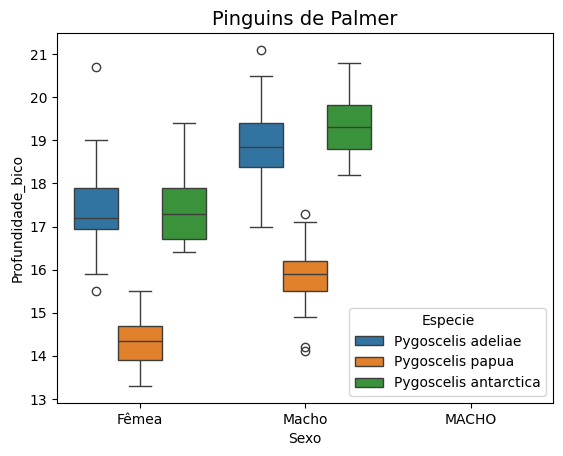

In [ ]:
# criano boxplot de sexo, profundidade de bico por espécie com seaborn
boxplot = sns.boxplot(x = df_analise["Sexo"],  y = df_analise["Profundidade_bico"], hue = df_analise["Especie"])
boxplot.set_ylabel("Profundidade_bico")
boxplot.set_title("Pinguins de Palmer", size = 14)

In [ ]:
# salvando como imagem
fig = boxplot.get_figure()
# preencha entre as aspas o caminho para salvar a imagem
# por exemplo fig.savefig("content/drive/MyDrive/Python/boxplot.png")
fig.savefig("")

In [ ]:
# apresentando plotnine e o ggplot2 do R dentro do Python
from plotnine import ggplot, aes, geom_point, geom_boxplot, theme_classic

/usr/local/lib/python3.13/dist-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 3 rows containing missing values.


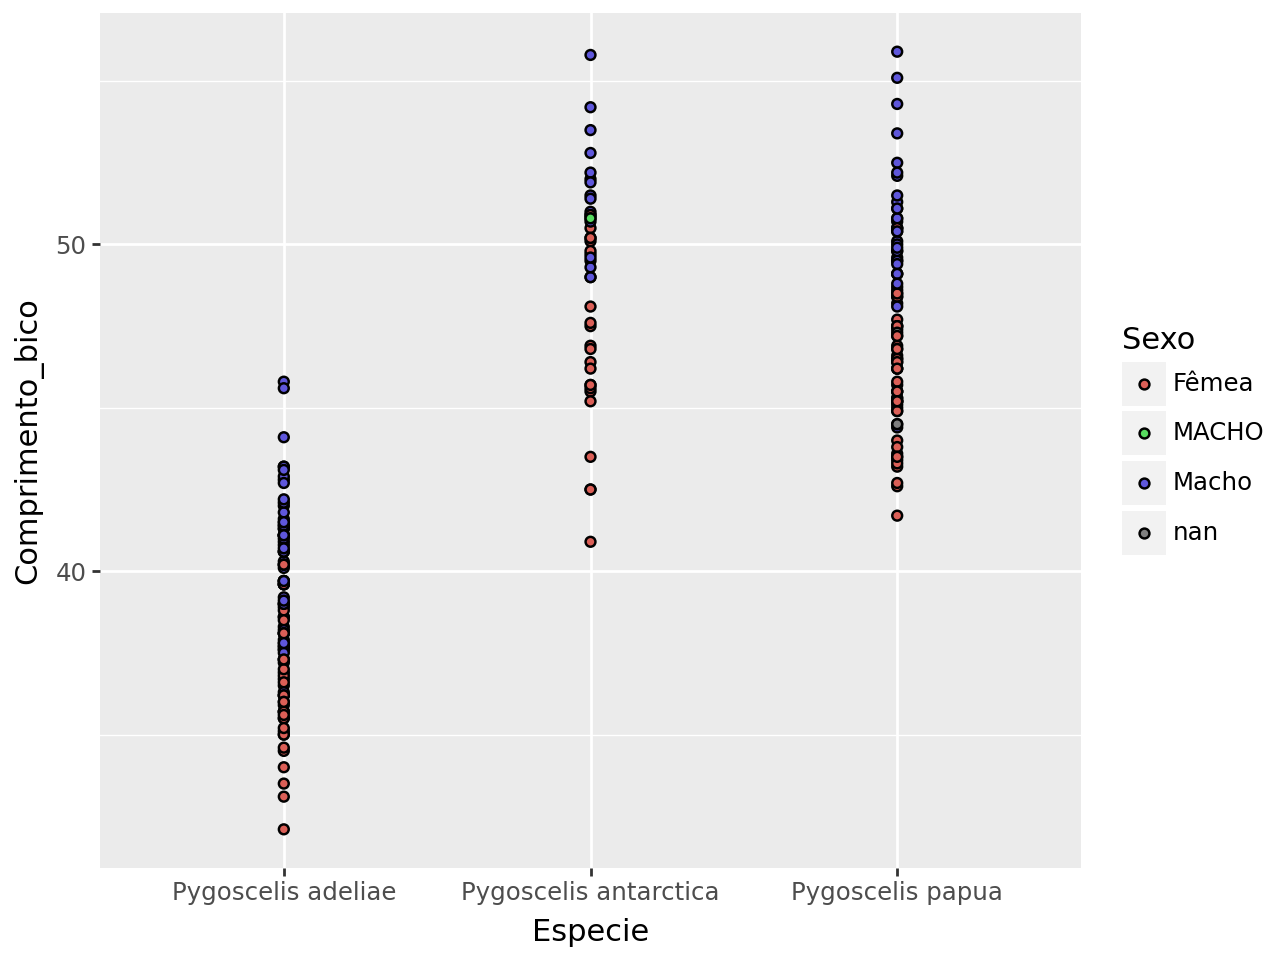

In [ ]:
# criando um gráfico de dispersão de comprimento de bico por espécie
ggplot(df_analise) + aes(x="Especie", y="Comprimento_bico", fill="Sexo") + geom_point()


/usr/local/lib/python3.13/dist-packages/plotnine/layer.py:284: PlotnineWarning: stat_boxplot : Removed 3 rows containing non-finite values.


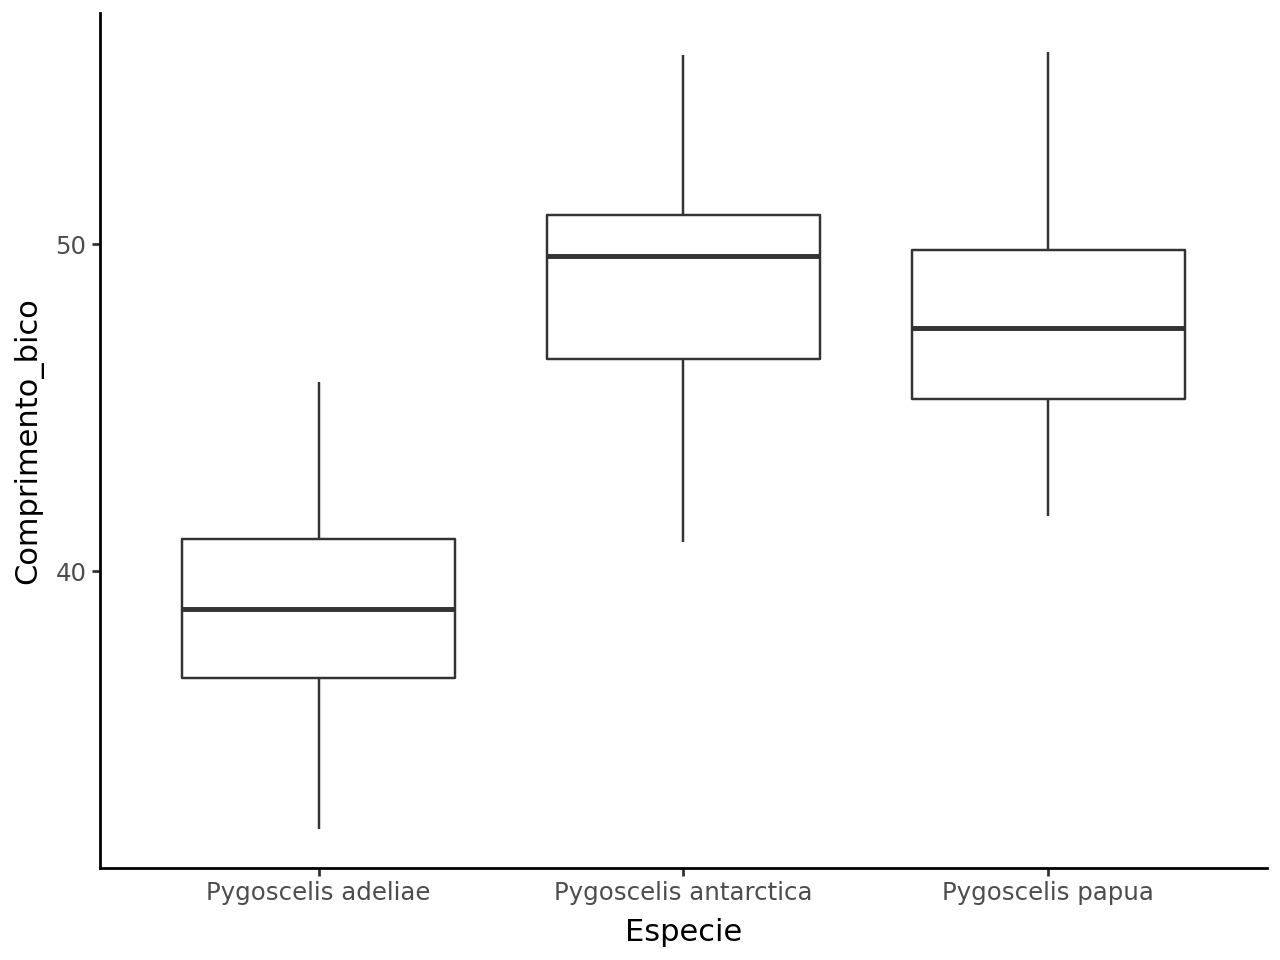

In [ ]:
# criando boxplot de comprimento de bico por espécie
ggplot(df_analise) + aes(x="Especie", y="Comprimento_bico") + geom_boxplot() + theme_classic()

# **Onde encontro referências de gráficos e códigos?**

## **[Python Graph Gallery](https://python-graph-gallery.com/)**

<img src= "https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.kdnuggets.com%2Fwp-content%2Fuploads%2Farya_make_amazing_visualizations_python_graph_gallery_4.png&f=1&nofb=1&ipt=550ff15a4b78877bd12851dc1abf49e92ac14db7ceb65c3c366f07abdde4ccee&ipo=images" width = 500>